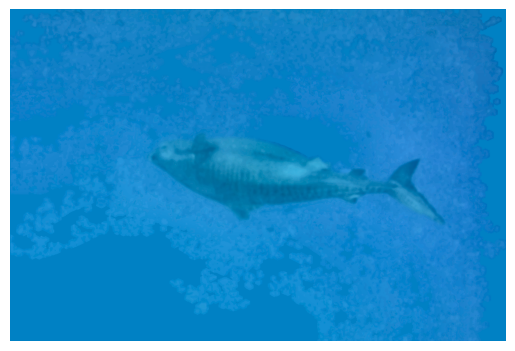

In [2]:
from pathlib import Path
import cv2 as cv
import numpy as np
import os
import matplotlib.pyplot as plt

# ---- minimal params ----
INPUT_PATH  = Path("data/raw/Shark 1.PNG")   # change for Shark 1 / cat
MODE   = "underwater"   # "underwater" or "silhouette"
ROTATE = True           # False for cat
CLAHE_CLIP = 3.0
KSIZE = 5
DILATE_IT = 2
PAD_FRAC = 0.15

# ensure project root
here = Path.cwd()
if not (here/"data"/"raw").exists():
    for _ in range(4):
        if (here.parent/"data"/"raw").exists():
            os.chdir(str(here.parent)); break
        here = here.parent

# ---- load ----
I = cv.imread(str(INPUT_PATH), cv.IMREAD_COLOR)
if I is None:
    raise FileNotFoundError(INPUT_PATH)
H, W = I.shape[:2]

# ---- enhance: bilateral → CLAHE(L) → light unsharp ----
den = cv.bilateralFilter(I, 7, 75, 75)
L, A, B = cv.split(cv.cvtColor(den, cv.COLOR_BGR2LAB))
L2 = cv.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=(8,8)).apply(L)
enh = cv.cvtColor(cv.merge([L2, A, B]), cv.COLOR_LAB2BGR)
blur = cv.GaussianBlur(enh, (0,0), 1.0)
enh  = cv.addWeighted(enh, 1.20, blur, -0.20, 0)

# ---- segmentation: Otsu (two simple modes) ----
if MODE == "underwater":
    lab = cv.cvtColor(enh, cv.COLOR_BGR2LAB); _,_,b = cv.split(lab)
    hsv = cv.cvtColor(enh, cv.COLOR_BGR2HSV); S    = hsv[:,:,1]
    _, th_b  = cv.threshold(b,       0, 255, cv.THRESH_BINARY+cv.THRESH_OTSU)
    _, s_inv = cv.threshold(255 - S, 0, 255, cv.THRESH_BINARY+cv.THRESH_OTSU)
    mask = cv.bitwise_and(th_b, s_inv)
    if (mask.sum()/255)/mask.size < 0.03:
        mask = cv.bitwise_or(th_b, s_inv)
else:
    g  = cv.cvtColor(enh, cv.COLOR_BGR2GRAY)
    gb = cv.GaussianBlur(g, (5,5), 0)
    inv = cv.normalize(255 - gb, None, 0, 255, cv.NORM_MINMAX)
    _, mask = cv.threshold(inv, 0, 255, cv.THRESH_BINARY+cv.THRESH_OTSU)

# ---- morphology tidy + largest blob ----
k = cv.getStructuringElement(cv.MORPH_ELLIPSE, (KSIZE, KSIZE))
mask = cv.morphologyEx(mask, cv.MORPH_CLOSE, k, iterations=1)
mask = cv.morphologyEx(mask, cv.MORPH_OPEN,  k, iterations=1)
if DILATE_IT > 0:
    mask = cv.dilate(mask, k, iterations=DILATE_IT)

num, labc = cv.connectedComponents(mask)
if num > 1:
    areas = [(labc==i).sum() for i in range(1, num)]
    mask  = (labc==(1+int(np.argmax(areas)))).astype(np.uint8)*255

area = (mask.sum()/255)/mask.size
if area < 0.005 or area > 0.98:
    final_img = enh
else:
    # ---- crop: rotate for underwater, box crop otherwise ----
    cnts,_ = cv.findContours(mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    cnt = max(cnts, key=cv.contourArea)
    if ROTATE:
        rect = cv.minAreaRect(cnt); angle = rect[-1]; (rw,rh) = rect[1]
        if rw < rh: angle += 90
        if angle < -45: angle += 90
        M = cv.getRotationMatrix2D((W//2, H//2), angle, 1.0)
        I_r = cv.warpAffine(enh,  M, (W,H), flags=cv.INTER_LINEAR,  borderMode=cv.BORDER_REFLECT)
        m_r = cv.warpAffine(mask, M, (W,H), flags=cv.INTER_NEAREST, borderMode=cv.BORDER_CONSTANT)
        cnt_t = cv.transform(cnt.reshape(-1,1,2).astype(np.float32), M).astype(np.int32)
        x,y,wc,hc = cv.boundingRect(cnt_t)
    else:
        x,y,wc,hc = cv.boundingRect(cnt)
        I_r, m_r = enh, mask

    pad = int(PAD_FRAC*min(W,H))
    x0 = max(0, x-pad); y0 = max(0, y-pad)
    x1 = min(W, x+wc+pad); y1 = min(H, y+hc+pad)
    crop  = I_r[y0:y1, x0:x1]
    mcrp  = m_r[y0:y1, x0:x1]

    # ---- minimal background fill (median of border) ----
    invm   = (mcrp==0).astype(np.uint8)*255
    border = np.zeros_like(invm)
    border[:10,:]=255; border[-10:,:]=255; border[:,:10]=255; border[:,-10:]=255
    samples = cv.bitwise_and(crop, crop, mask=cv.bitwise_and(invm, border)).reshape(-1,3)
    samples = samples[(samples.sum(1)>0)]
    bg = (210,220,230) if len(samples)==0 else tuple(map(int, np.median(samples,0)))
    canvas = np.full_like(crop, bg, dtype=np.uint8)
    final_img = cv.add(cv.bitwise_and(crop,  crop,  mask=mcrp),
                       cv.bitwise_and(canvas, canvas, mask=cv.bitwise_not(mcrp)))

# ---- display single output ----
plt.imshow(cv.cvtColor(final_img, cv.COLOR_BGR2RGB)); plt.axis("off"); plt.show()
